# Project 2

Welcome to the second NLP1 project. The goal of the second tutorial was to get you familiar with using pre-trained embeddings and moving towards a compositional encoder for text classification.

Given the skills you have developed in the last week, you will now be applying them within the dataset and task you have chosen during Project 1. You will be applying hands-on the experiments you have already explored in the Tutorial 2, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and errors analyses, and tackling your own research questions. 


The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

# Get to work!

1. Find a word embedding model that is appropriate for your dataset. Think about the language, the kind of text you are working with. Find evidence that your choice is a good one: 
    * Can you tokenize your texts in a way coherent with the definition of a token in the embedding model?
    * Does the model's vocabulary give enough coverage to the words in your texts? etc.
2. Explore what your chosen word embedding model captures. Some things you might consider: 
    * Is it good at representing interesting similarities (re to your choice of task)? J
    * Have you found task-specific evidence that it's better than some other reasonable alternative?
    * Do you know about limitations of this model?
    * Any limitations that you find particularly troubling for your task? 
3. Experiment with the embed-and-pool approach.  
    * What design choices have meaningful impact in classification performance (eg, embedding size, architecture design, optimisation parameters), if any?
    * Is this better than what you could achieve last week? In other words, did pretrained embeddings add to your design?
4. Experiment with a recurrent encoder (GRU or LSTM). 
    * What design choices have meaningful impact in classification performance, if any?
    * Did you investigate the impact of data size, embedding parameters (trained or not, fixed or trainable, etc)?
    * Did you struggle with over-fitting?
    * How far can this approach go? Are you able to improve meaningfully on embed-and-pool?
5. We make decisions under uncertainty all the time, are you gathering enough information to substantiate your choices? Various things can lead to small differences in results, and these differences are not always consistent. Here are some things to think about:
    * How did you structure you hyperparameter search?
    * Are you keeping an eye on experimental variance?
6. Experiment with error analysis and try to discover what characteristics of input texts are predictive of performance differences across major design choices. 
    * What analysis features did you come up with?
    * Which ones did you manage to test and how did that go?
    * What would you prioritise in the future in order to improve your systems?

Be mindful that you will be using your experiments to write up your final blog, so make sure your code is clean and neat!

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

# Tips

## Pretrained embedding models

We will post a list with some options for you. 

## Features for analysis

Features that you can interpret as an aspect of _complexity_ in light of your task's goals.

- length
- presence of rare/common words, including unknown words
- syntactic features (like parts-of-speech, syntactic complexity, syntactic voice, presence of negation, etc.)
- semantic features (eg, the average similarity of the text to training documents or some curated set of training documents, presence of words in certain semantic classes, etc.)
- task-specific features (eg, 
- model-specific features (eg, predicted label, probability assigned to predicted label, number of parameters or layers or some other model descriptor)

## 1. Choosing a word embedding model

Bias in Bios consists of English, third-person biographies scraped from the web (Common Crawl). The register is formal and encyclopedic, with many named entities (universities, hospitals, companies) and domain terms (medical, legal, academic). We therefore need an English model trained on, or covering, formal written text with a large vocabulary. The options from the list:

| Model | Training data | Fit for our data |
|---|---|---|
| **GloVe 2024 Wiki-Gigaword** | Wikipedia + Gigaword newswire (2024), 1.3M lowercased words | formal encyclopedic/news text, recent vocabulary |
| **fastText wiki-news-300d-1M** | Wikipedia 2017 + UMBC + news, 1M cased words | similar register; the `.vec` file has no subword vectors, so there is no OOV advantage |
| **ConceptNet Numberbatch 19.08 (English)** | ConceptNet knowledge graph combined with word2vec/GloVe, 517k words and phrases | contains multi-word terms such as `software_engineer`, and according to its authors it was built to be less stereotyped; both are relevant for our task |
| Kyubyong word2vec | Wikipedia, ~30 languages | **not tried**: the repository has no English model (it explicitly targets non-English languages) |

We compare the three English candidates, all at 300 dimensions so that dimensionality does not confound the comparison.

In [1]:
import re
from collections import Counter
from pathlib import Path
from urllib.request import urlretrieve

import nltk
import numpy as np
from datasets import load_dataset
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

import clslib

nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

ds = load_dataset("LabHC/bias_in_bios")
professions = [
    "accountant", "architect", "attorney", "chiropractor", "comedian", "composer",
    "dentist", "dietitian", "dj", "filmmaker", "interior_designer", "journalist",
    "model", "nurse", "painter", "paralegal", "pastor", "personal_trainer",
    "photographer", "physician", "poet", "professor", "psychologist", "rapper",
    "software_engineer", "surgeon", "teacher", "yoga_teacher",
]

In [2]:
# WARNING: this will download large files (~2.7gb total), this wil take around 10 to 15min
EMB_DIR = Path.home() / ".cache" / "embeddings"  # large files, so kept outside the repo
EMBEDDINGS = {  # name: (url, dimensionality, file starts with a header line)
    "glove": ("https://downloads.cs.stanford.edu/nlp/data/wordvecs/glove.2024.wikigiga.300d.zip", 300, False),
    "fasttext": ("https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip", 300, True),
    "numberbatch": ("https://conceptnet.s3.amazonaws.com/downloads/2019/numberbatch/numberbatch-en-19.08.txt.gz", 300, True),
}

def load_embeddings(url, dims, skip_first_line):
    path = EMB_DIR / url.split("/")[-1]
    if not path.is_file():
        EMB_DIR.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return clslib.PretrainedEmbeddings(str(path), dims, skip_first_line=skip_first_line)

emb = {name: load_embeddings(*spec) for name, spec in EMBEDDINGS.items()}  # a few minutes
for name, model in emb.items():
    print(name, model.vectors.shape)

glove (1287615, 300)
fasttext (830463, 300)
numberbatch (516784, 300)


### Tokenization

The GloVe vocabulary contains Penn Treebank-style tokens (punctuation split off, `n't`, `'s`, and quotes written as ` `` ` and `''`). That is the convention NLTK's `word_tokenize` follows, and `clslib.BasicTokenizer` uses it. So we lowercase (all vocabularies are lowercased by `PretrainedEmbeddings`), keep punctuation, and tokenize with NLTK.

Numberbatch uses a different convention: lowercase words and phrases joined with `_`, no punctuation tokens, and numbers of two or more digits written with `#` (`2012` → `####`). `to_vocab` maps our tokens to that number convention. In the example below, out-of-vocabulary (OOV) tokens are shown in [brackets].

In [3]:
tokenizer = clslib.BasicTokenizer(lowercase=True, remove_punct=False, remove_stopwords=False)

def to_vocab(name, tokens):
    """Map tokens to the model's convention: Numberbatch writes numbers of 2+ digits with '#' (2012 -> ####)."""
    if name == "numberbatch":
        return [re.sub(r"\d", "#", t) if re.search(r"\d\d", t) else t for t in tokens]
    return tokens

example = ds["train"][0]["hard_text"]
for name, model in emb.items():  # out-of-vocabulary tokens in [brackets]
    print(f"{name}:", " ".join(t if t in model else f"[{t}]" for t in to_vocab(name, tokenizer.tokens(example))))

glove: he is also the project lead of and major contributor to the open source [assembler/simulator] `` [easy68k] . '' he earned a master ’ s degree in computer science from the university of [michigan-dearborn] , where he is also an adjunct instructor . [downloads/updates]
fasttext: he is also the project lead of and major contributor to the open source [assembler/simulator] [``] [easy68k] . [''] he earned a master ’ s degree in computer science from the university of michigan-dearborn , where he is also an adjunct instructor . [downloads/updates]
numberbatch: he is also the project lead of and major contributor to the open source [assembler/simulator] [``] [easy##k] [.] [''] he earned a master [’] s degree in computer science from the university of [michigan-dearborn] [,] where he is also an adjunct instructor [.] [downloads/updates]


In [4]:
counts = Counter(t for text in ds["train"]["hard_text"] for t in tokenizer.tokens(text))  # a few minutes

for name, model in emb.items():
    oov = Counter({t: c for t, c in counts.items() if to_vocab(name, [t])[0] not in model})
    print(f"{name}: type coverage {1 - len(oov) / len(counts):.1%}, token coverage {1 - oov.total() / counts.total():.2%}")
    print("  most frequent OOV tokens:", [t for t, _ in oov.most_common(15)])
    print("  professions not in vocabulary:", [p for p in professions if p not in model])

glove: type coverage 52.9%, token coverage 98.25%
  most frequent OOV tokens: ['cross/blue', 'in-network', '5.', 'freeones', '2012.', '2013.', '..', '2011.', '2010.', 'lybrate.com', '2009.', '2008.', '2007.', '2014.', '2006.']
  professions not in vocabulary: ['interior_designer', 'personal_trainer', 'software_engineer', 'yoga_teacher']
fasttext: type coverage 53.3%, token coverage 98.66%
  most frequent OOV tokens: ["''", '``', 'cross/blue', 'freeones', 'lybrate.com', "n't", 'hospital/clinic', 'and/or', 'complete/partial', 'cosmetic/', 'hiv/aids', '2018.', 'self-pay/uninsured', 'multispeciality', 'treatment/']
  professions not in vocabulary: ['interior_designer', 'personal_trainer', 'software_engineer', 'yoga_teacher']
numberbatch: type coverage 27.8%, token coverage 83.44%
  most frequent OOV tokens: [',', '.', ')', '(', 'dr.', '’', "'s", ':', 'ms.', '&', ';', '”', '“', 'ph.d.', 'mr.']
  professions not in vocabulary: ['yoga_teacher']


**Coverage.** For GloVe and fastText only ~53% of the word *types* are in the vocabulary, but these are rare types: 98.3% (GloVe) and 98.7% (fastText) of the *tokens* are covered. The remaining OOV tokens are mostly slash compounds (`cross/blue`, `hospital/clinic`), website names (`lybrate.com`) and rare names, which all map to the same `<unk>` vector. Numberbatch covers only 83.4% of the tokens. Almost all of its OOV tokens are punctuation, abbreviations with a full stop (`dr.`, `ph.d.`) and `'s`. These are tokens our tokenizer produces but Numberbatch never contains, so its token definition is the least coherent with our tokenization.

**Coherence with the tokenizer.** NLTK's quote tokens and `n't` are the most frequent OOV tokens for fastText, while GloVe knows them, so our tokenizer matches GloVe's definition of a token best. GloVe's slightly lower token coverage comes from hyphenated words (`in-network`) and from one tokenizer artifact. Years followed by a full stop (`2012.`) stay one token, because `BasicTokenizer` lowercases *before* NLTK's sentence splitter runs, and the splitter then misses the sentence boundary. This affects only ~0.2% of tokens, so we accept it.

**Labels.** The four multi-word professions (`interior_designer`, `personal_trainer`, `software_engineer`, `yoga_teacher`) are not in GloVe or fastText. Numberbatch has all of them except `yoga_teacher`. Below, a profession that is missing is represented as the average of its words. Note that our tokenizer splits the bios themselves into single words, so Numberbatch's phrases only help for the labels, not for the texts.

## 2. What does the embedding model capture?

### Similarities between professions

The nearest neighbours (cosine similarity) of some profession words:

In [5]:
unit = {name: m.vectors / np.maximum(np.linalg.norm(m.vectors, axis=1, keepdims=True), 1e-8) for name, m in emb.items()}

def neighbours(name, word, k=8):
    """The k nearest words (cosine similarity) to `word`, excluding the word itself."""
    sims = unit[name] @ unit[name][emb[name].index(word)]
    return [emb[name].word(i) for i in np.argsort(-sims)[1:k + 1]]

for word in ["surgeon", "nurse", "professor", "pastor", "dj", "model"]:
    for name in emb:
        print(f"{word:9s} {name:11s}", neighbours(name, word))

surgeon   glove       ['physician', 'orthopedic', 'surgeons', 'doctor', 'dentist', 'surgery', 'dr.', 'cardiologist']
surgeon   fasttext    ['surgeons', 'doctor', 'neurosurgeon', 'surgery', 'physician', 'surgical', 'anesthesiologist', 'medic']
surgeon   numberbatch ['supersurgeon', 'hand_surgeon', 'aesthetic_surgeon', 'cardiothoracic_surgeon', 'cosmetic_surgeon', 'surgeoness', 'microsurgeon', 'plastic_surgeon']
nurse     glove       ['nurses', 'nursing', 'midwife', 'doctor', 'physician', 'hospital', 'mother', 'teacher']
nurse     fasttext    ['nurses', 'nursing', 'doctor', 'midwife', 'anesthetist', 'physician', 'hospital', 'matron']
nurse     numberbatch ['nonnurse', 'scrub_nurse', 'visiting_nurse', 'care_worker', 'telenurse', 'nurseth', 'nursest', 'nursy']
professor glove       ['university', 'lecturer', 'sociology', 'emeritus', 'associate', 'scientist', 'harvard', 'researcher']
professor fasttext    ['prof.', 'prof', 'dr.', 'dr', 'mr.', 'professsor', 'emeritus', 'mr']
professor number

GloVe's neighbours are mostly *topically related* words (professor -> university, sociology, harvard; pastor -> baptist, church). fastText's are more often spelling or morphological variants (prof., professsor; djs, deejay, d.j.). Numberbatch's are lexical relations from the knowledge graph: derived forms and subtypes (hand_surgeon, plastic_surgeon; nonnurse, scrub_nurse; professoress). Topical relatedness is what helps us: a professor's bio mentions universities and fields of study, not "prof." or "full_professor".

A limitation of all three models is that they are static, with one vector per word type. `model` therefore ends up near concept/prototype/framework (the scientific or product sense), while our class means a fashion model. Only Numberbatch places a fashion sense (heidi_klum) among the neighbours, mixed with the other senses.

### Gender

Since the dataset is about gender bias, we place each profession on the she-he direction (cos(profession, she) - cos(profession, he)). We then correlate that score with the actual share of women per profession in the training data.

In [6]:
def profession_vectors(name):
    """Unit vector per profession; a multi-word profession (e.g. yoga_teacher) that is not in the vocabulary averages its words."""
    words = [[p] if p in emb[name] else p.split("_") for p in professions]
    P = np.stack([unit[name][[emb[name].index(w) for w in ws]].mean(0) for ws in words])
    return P / np.linalg.norm(P, axis=1, keepdims=True)

n_prof = Counter(ds["train"]["profession"])
n_female = Counter(p for p, g in zip(ds["train"]["profession"], ds["train"]["gender"]) if g == 1)
female_share = [n_female[i] / n_prof[i] for i in range(len(professions))]

for name, model in emb.items():
    P = profession_vectors(name)
    she_minus_he = P @ unit[name][model.index("she")] - P @ unit[name][model.index("he")]
    ranked = [professions[i] for i in np.argsort(she_minus_he)]
    print(f"{name}: Spearman rho with female share in data = {spearmanr(she_minus_he, female_share)[0]:.2f}")
    print("  closest to 'he':", ranked[:4], " closest to 'she':", ranked[-4:])

glove: Spearman rho with female share in data = 0.60
  closest to 'he': ['software_engineer', 'architect', 'personal_trainer', 'pastor']  closest to 'she': ['psychologist', 'paralegal', 'nurse', 'dietitian']
fasttext: Spearman rho with female share in data = 0.78
  closest to 'he': ['software_engineer', 'architect', 'rapper', 'comedian']  closest to 'she': ['yoga_teacher', 'dietitian', 'paralegal', 'nurse']
numberbatch: Spearman rho with female share in data = 0.52
  closest to 'he': ['architect', 'poet', 'filmmaker', 'pastor']  closest to 'she': ['teacher', 'yoga_teacher', 'dietitian', 'paralegal']


All three models encode gender stereotypes about professions: the closer a profession lies to "she", the larger the share of women in our data. The Spearman ρ is 0.60 for GloVe, 0.78 for fastText and 0.52 for Numberbatch. With only 28 professions these estimates are noisy, so the difference between GloVe and Numberbatch is not meaningful. Numberbatch's design against stereotypes therefore shows at most a modest effect here.

This is the limitation we find most troubling for our task. Bios contain many gendered words (pronouns, first names), and through the embeddings a classifier can link these to professions. It would then reproduce exactly the bias that Bias in Bios is designed to measure.

### Task-specific comparison

As a quick probe, we mean-pool the embeddings of a bio's content words (stopwords and punctuation removed) and train a logistic regression on 20k training bios, evaluating on 5k dev bios. Because the classes are imbalanced (30% professor), we report macro-F1 alongside accuracy.

In [7]:
content_tokenizer = clslib.BasicTokenizer(lowercase=True, remove_punct=True, remove_stopwords=True)
probe_train = ds["train"].shuffle(seed=42).select(range(20_000))
probe_dev = ds["dev"].shuffle(seed=42).select(range(5_000))

def mean_pool(name, texts):
    model = emb[name]
    return np.stack([model.vectors[[model.index(t) for t in to_vocab(name, content_tokenizer.tokens(x))]].mean(0) for x in texts])

for name in emb:
    clf = LogisticRegression(max_iter=2000).fit(mean_pool(name, probe_train["hard_text"]), probe_train["profession"])
    pred = clf.predict(mean_pool(name, probe_dev["hard_text"]))
    print(f"{name}: accuracy {accuracy_score(probe_dev['profession'], pred):.3f}, "
          f"macro-F1 {f1_score(probe_dev['profession'], pred, average='macro'):.3f}")

glove: accuracy 0.751, macro-F1 0.624
fasttext: accuracy 0.734, macro-F1 0.527
numberbatch: accuracy 0.681, macro-F1 0.387


GloVe scores highest on both metrics (accuracy 0.751, macro-F1 0.625), followed by fastText (0.735, 0.528) and Numberbatch (0.681, 0.386). The largest gaps are in macro-F1, so the differences show up mostly on the smaller professions. Numberbatch's weak score fits its neighbours: it encodes lexical relations between words, whereas classifying a bio relies on which words co-occur with a profession (topic). This is a single sample with a single seed, so we have no variance estimate here. The macro-F1 gaps (≥ 0.10) are large enough to base our choice on, and we will compare with cross-validation in the embed-and-pool experiments.

### Conclusion

We choose GloVe 2024 Wiki-Gigaword, 300d: its tokens match our NLTK tokenization, it covers 98.3% of the tokens, its neighbours are topically meaningful for professions, and it gives the best task probe. Its limitations for our task:
- Gender bias: profession vectors lie closer to "she" or "he" in line with real-world stereotypes (see above). This is the most troubling one.
- Static vectors: one vector per word, no context (model).
- No subwords: rare names, compounds and URLs all share the `<unk>` vector.
- No multi-word terms: professions such as software_engineer are not single tokens.
- Lowercased: casing information (names, acronyms) is lost.
- Domain: trained on Wikipedia/news, not on web bios, so terms from e.g. healthcare listings (in-network, cross/blue) are missing.

## 3. Embed and Pool

* What design choices have meaningful impact in classification performance (eg, embedding size, architecture design, optimisation parameters), if any?
* Is this better than what you could achieve last week? In other words, did pretrained embeddings add to your design?

In [ ]:

import time
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Experiment settings
POOLING_METHODS = ["mean", "max", "mean_max"]
C_VALUES = [0.01, 0.1, 1.0, 10.0]

# Keep the same dataset split for every experiment
X_train_text = probe_train["hard_text"]
X_dev_text = probe_dev["hard_text"]

y_train = probe_train["profession"]
y_dev = probe_dev["profession"]


# 1. Create text representations using different pooling methods
def pool_text(name, text, pooling):
    model = emb[name]

    tokens = to_vocab(
        name,
        content_tokenizer.tokens(text)
    )

    # Convert tokens into embedding vectors
    indices = [model.index(t) for t in tokens]

    # Handle empty texts
    if len(indices) == 0:
        if pooling == "mean_max":
            return np.zeros(600, dtype=np.float32)
        return np.zeros(300, dtype=np.float32)

    vectors = model.vectors[indices]

    # Mean pooling
    mean_vector = vectors.mean(axis=0)

    if pooling == "mean":
        return mean_vector

    # Max pooling
    max_vector = vectors.max(axis=0)

    if pooling == "max":
        return max_vector

    # Combine mean and max pooling
    if pooling == "mean_max":
        return np.concatenate([mean_vector, max_vector])

    raise ValueError(f"Unknown pooling method: {pooling}")


def create_features(name, texts, pooling):
    return np.stack([
        pool_text(name, text, pooling)
        for text in texts
    ])


# 2. Run experiments for all embedding models
results = []

for name in emb.keys():

    print(f"\nTesting embedding model: {name}")

    for pooling in POOLING_METHODS:

        print(f"  Pooling: {pooling}")

        # Generate representations
        X_train = create_features(name, X_train_text, pooling)
        X_dev = create_features(name, X_dev_text, pooling)

        for c in C_VALUES:

            clf = LogisticRegression(
                C=c,
                max_iter=2000,
                solver="lbfgs",
                random_state=42
            )

            # Measure classifier training time
            start = time.perf_counter()

            clf.fit(X_train, y_train)

            training_time = time.perf_counter() - start

            # Evaluate on development data
            predictions = clf.predict(X_dev)

            accuracy = accuracy_score(y_dev, predictions)
            macro_f1 = f1_score(
                y_dev,
                predictions,
                average="macro"
            )

            results.append({
                "embedding": name,
                "pooling": pooling,
                "C": c,
                "accuracy": accuracy,
                "macro_f1": macro_f1,
                "training_time": training_time
            })

        del X_train, X_dev


# 3. Display results
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="macro_f1",
    ascending=False
).reset_index(drop=True)

print("\nAll experimental results:")
display(results_df.round(4))


# 4. Find the best configuration for each embedding model
best_per_model = (
    results_df
    .loc[results_df.groupby("embedding")["macro_f1"].idxmax()]
    .sort_values("macro_f1", ascending=False)
)

print("\nBest configuration per embedding:")
display(best_per_model.round(4))


# 5. Compare the best embedding models
print("\nOverall best configuration:")
display(results_df.head(1).round(4))


# 6. Save results for the project report
results_df.to_csv("embed_pool_results.csv", index=False)


Here we experimented with a few settings and parameters. We used 3 different pooling strategies: mean, max and both combined. To analyse the results we mainly use macro-f1 score, because it best represents the score on our clasification task. We also introduced a regularisation parameter in the model.

First off it is quite clear that a higher regularisation performs better overall. 
For the pooling strategy there is not a clear winner overall. This seems to be more dependent on the embedding model, altough we can say that max pooling is probably not the best strategy.
The best configuration is fasttext with mean pooling and regularisation of 10, but the top 3 models don't show a big difference.

This is experiment is only run on a small portion of the data to save computation time, so it may not be representative to the whole dataset.

## 4. Recurrent Encoders (GRU or LSTM)

Training handled in train.py

Trained the following

<input type="checkbox"/> `python train.py --model gru lstm --embedding glove fasttext numberbatch --batch-size 128`

<input type="checkbox"/> `python train.py --model gru lstm --embedding glove fasttext numberbatch --num-workers 4 --bidirectional`

<input type="checkbox"/> `python train.py --model gru lstm --embedding glove fasttext numberbatch --num-workers 4 --bidirectional --num-layers 2`

<input type="checkbox"/> `python train.py --model gru lstm --embedding glove fasttext numberbatch --num-workers 4 --train-embeddings`

<input type="checkbox"/> `python train.py --model gru lstm --embedding glove fasttext numberbatch --num-workers 4 --batch-size 1024 --hidden-size 64`

<input type="checkbox"/> `python train.py --model gru lstm --embedding glove fasttext numberbatch --num-workers 4 --batch-size 1024 --bidirectional --num-layers 2`

<input type="checkbox"/> `python train.py --model gru lstm --embedding glove fasttext numberbatch --num-workers 4 --batch-size 1024 --bidirectional --num-layers 2 --hidden-size 256 --num-layers 2`

- We tested with different types encoders, bidirectional encoders, embeddings, and the number of classifier layers. Currently no design choices seem to have a meaningful impact on classifcation performance.

- `#TODO` Test with trainable embeddings, data size (trainable mebeddings causes extreem overfitting)

- Overfitting seemed mainly determined by the embedding type. Using glove overfitting was more probable, It mainly happend after epoch 6. With Fasttext some experiments started overfitting. While with numberbatch little to no experiments started overfitting.

- `#TODO` compare with embed and pool

## 5. Uncertain decisions

- We first started with some changing single parameters from the default values. Than with a parallel coordinates plot we looked at the trends of which settings contributed higher scores. With these we tried to futher increase scores.
- Each setting is run at least 3 times. The final results were the mean values over all of the runs. Additionally each experiment could be analysed per run.

## 6. Error analysis

Accuracy: 0.751
Macro-F1: 0.624

Classification report:
              precision    recall  f1-score   support

           0       0.63      0.66      0.64        67
           1       0.74      0.61      0.67       146
           2       0.82      0.86      0.84       434
           3       0.73      0.23      0.35        35
           4       0.69      0.50      0.58        36
           5       0.71      0.73      0.72        75
           6       0.88      0.88      0.88       169
           7       0.71      0.67      0.69        55
           8       0.61      0.65      0.63        17
           9       0.79      0.71      0.75        83
          10       0.25      0.10      0.14        10
          11       0.65      0.73      0.69       239
          12       0.65      0.66      0.66        86
          13       0.78      0.74      0.76       238
          14       0.73      0.77      0.75        84
          15       1.00      0.07      0.14        27
          16       0.58  

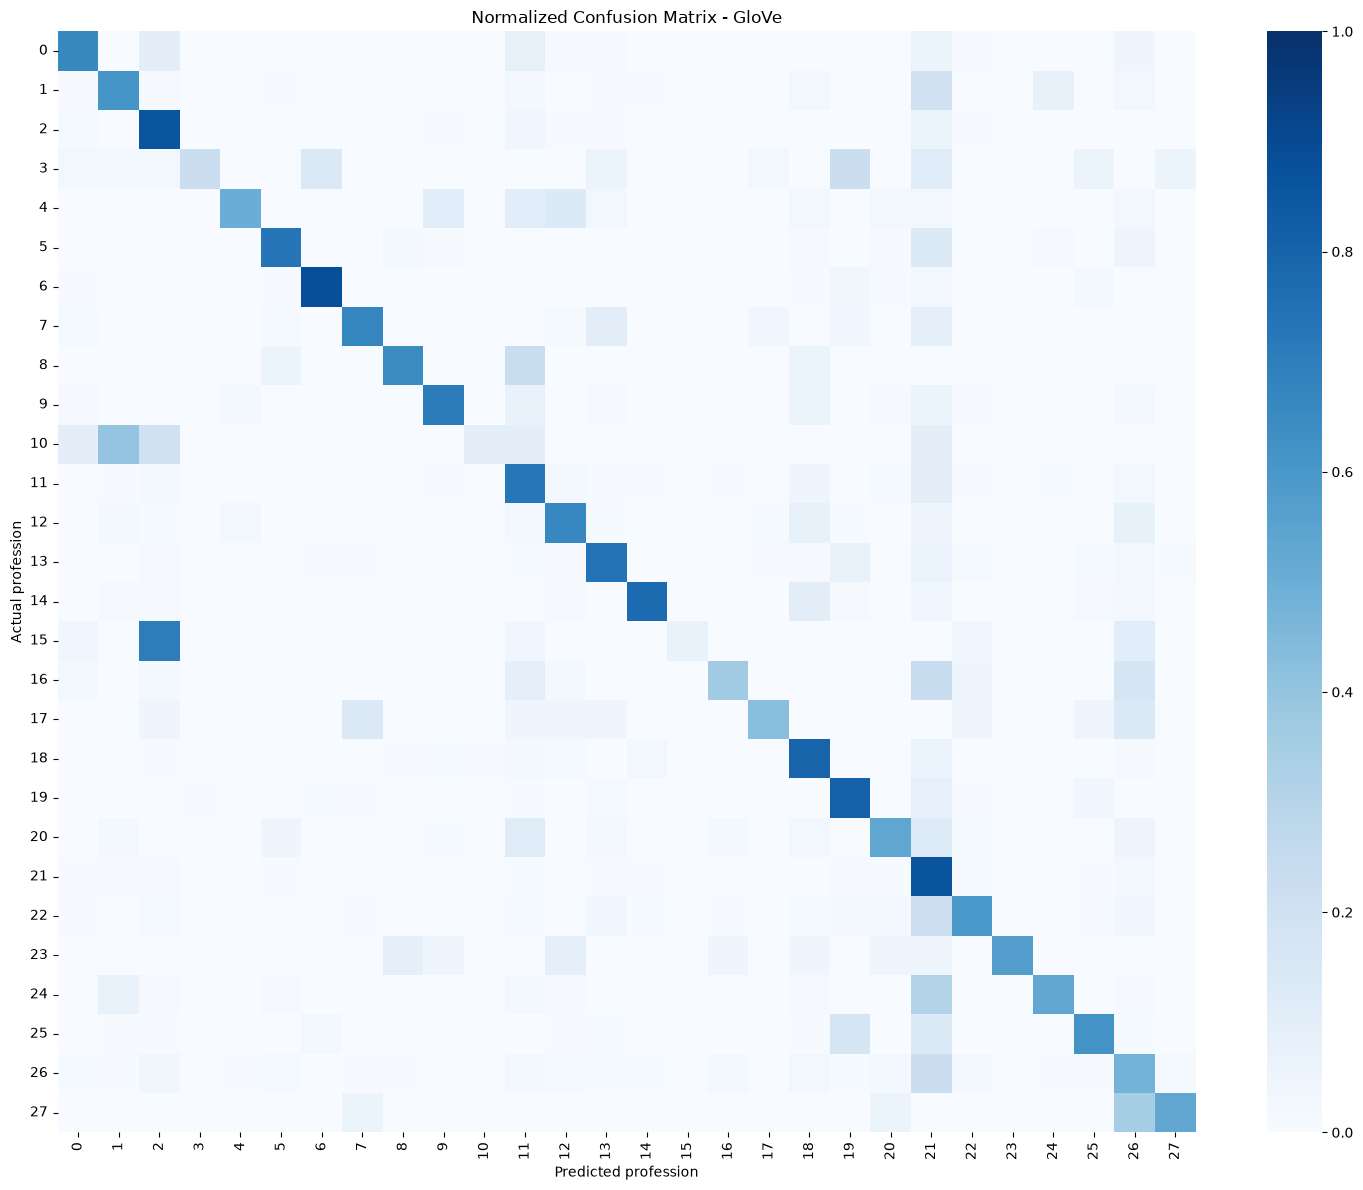

In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    f1_score,
    classification_report
)

# Recreate the GloVe baseline
# Uses the same 20k training and 5k development split as your notebook

X_train = mean_pool("glove", probe_train["hard_text"])
X_dev = mean_pool("glove", probe_dev["hard_text"])

y_train = probe_train["profession"]
y_true = np.array(probe_dev["profession"])

clf = LogisticRegression(max_iter=2000, random_state=42)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_dev)

print("Accuracy:", round(accuracy_score(y_true, y_pred), 3))
print("Macro-F1:", round(
    f1_score(y_true, y_pred, average="macro"), 3
))

print("\nClassification report:")
print(classification_report(y_true, y_pred, zero_division=0))


# CONFUSION MATRIX

labels = sorted(set(y_true) | set(y_pred))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels,
    normalize="true"
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    vmin=0,
    vmax=1
)

plt.title("Normalized Confusion Matrix - GloVe")
plt.xlabel("Predicted profession")
plt.ylabel("Actual profession")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


  length_group  accuracy  number_of_bios  mean_length
0   Q1 (short)     0.703          1287.0       18.853
1           Q2     0.719          1238.0       28.635
2           Q3     0.797          1288.0       41.949
3    Q4 (long)     0.784          1187.0       64.776


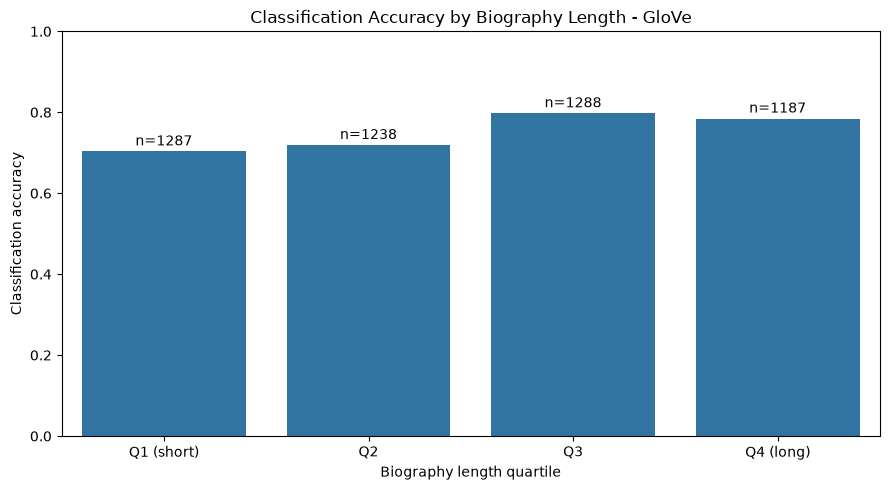

In [9]:

# BIOGRAPHY LENGTH ANALYSIS

# Calculate the number of tokens in each biography
lengths = np.array([
    len(content_tokenizer.tokens(text))
    for text in probe_dev["hard_text"]
])

length_df = pd.DataFrame({
    "true_label": y_true,
    "predicted_label": y_pred,
    "length": lengths
})

# Divide biographies into four equally sized groups
length_df["length_group"] = pd.qcut(
    length_df["length"],
    q=4,
    labels=["Q1 (short)", "Q2", "Q3", "Q4 (long)"],
    duplicates="drop"
)

# Calculate accuracy and number of biographies per group
length_results = (
    length_df
    .groupby("length_group", observed=True)
    .apply(
        lambda x: pd.Series({
            "accuracy": accuracy_score(
                x["true_label"],
                x["predicted_label"]
            ),
            "number_of_bios": len(x),
            "mean_length": x["length"].mean()
        }),
        include_groups=False
    )
    .reset_index()
)

print(length_results.round(3))


# BARPLOT

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=length_results,
    x="length_group",
    y="accuracy"
)

plt.title("Classification Accuracy by Biography Length - GloVe")
plt.xlabel("Biography length quartile")
plt.ylabel("Classification accuracy")
plt.ylim(0, 1)

# Add sample sizes above bars
for i, row in length_results.iterrows():
    ax.text(
        i,
        row["accuracy"] + 0.015,
        f'n={int(row["number_of_bios"])}',
        ha="center"
    )

plt.tight_layout()
plt.show()
